## Task 1: Data Preparation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

np.random.seed(42)

data = load_breast_cancer()
X, y = data.data, data.target    
class_names = list(data.target_names) 
print("X shape:", X.shape, "| classes:", dict(zip(*np.unique(y, return_counts=True))), class_names)


X shape: (569, 30) | classes: {np.int64(0): np.int64(212), np.int64(1): np.int64(357)} [np.str_('malignant'), np.str_('benign')]


In [2]:
def train_test_split(x, y, test_size=0.2, seed=42):
    np.random.seed(seed)
    
    train_indices = []
    test_indices = []
    
    classes = np.unique(y)
    
    for cls in classes:
        cls_indices = np.where(y == cls)[0]
        np.random.shuffle(cls_indices)
        split_index = int(len(cls_indices) * (1 - test_size))
        train_indices.extend(cls_indices[:split_index])
        test_indices.extend(cls_indices[split_index:])

    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)
    
    np.random.shuffle(train_indices)
    np.random.shuffle(test_indices)
    
    return x[train_indices], x[test_indices], y[train_indices], y[test_indices]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, seed=42)

def show_counts(name, labels):
    cls, cnt = np.unique(labels, return_counts=True)
    print(f"{name} n={len(labels)} | " +
        " | ".join(f"{class_names[c]}: {n} ({n/len(labels):.1%})" for c, n in zip(cls, cnt)))

show_counts("Full", y); show_counts("Train", y_train); show_counts("Test", y_test)

Full n=569 | malignant: 212 (37.3%) | benign: 357 (62.7%)
Train n=454 | malignant: 169 (37.2%) | benign: 285 (62.8%)
Test n=115 | malignant: 43 (37.4%) | benign: 72 (62.6%)


## Task 2: Implement GausianNaiveBayes

In [3]:
class GaussianNaiveBayes:
    def fit(self, x_train, y_train):
        x_train = np.asarray(x_train, dtype=float)
        y_train = np.asarray(y_train)
        self.classes_ = np.unique(y_train)
        n_classes = len(self.classes_)
        n_features = x_train.shape[1]

        self.theta_ = np.zeros((n_classes, n_features))
        self.var_ = np.zeros((n_classes, n_features))
        self.class_prior_ = np.zeros(n_classes)

        for idx, cls in enumerate(self.classes_):
            x_cls = x_train[y_train == cls]
            self.theta_[idx, :] = np.mean(x_cls, axis=0)
            self.var_[idx, :] = np.var(x_cls, axis=0)
            self.class_prior_[idx] = x_cls.shape[0] / x_train.shape[0]
        return self

    def _joint_log_likelihood(self, X):
        X = np.asarray(X, dtype=float)
        log_norm = -0.5 * np.sum(np.log(2 * np.pi * self.var_), axis=1)
        sq = (X[:, None, :] - self.theta_[None, :, :]) ** 2 / self.var_[None, :, :]
        return np.log(self.class_prior_) + log_norm - 0.5 * sq.sum(axis=2)

    def predict_proba(self, X):
        jll = self._joint_log_likelihood(X)
        m = jll.max(axis=1, keepdims=True)
        log_evidence = m + np.log(np.exp(jll - m).sum(axis=1, keepdims=True))
        return np.exp(jll - log_evidence)

    def predict(self, X):
        return self.classes_[np.argmax(self._joint_log_likelihood(X), axis=1)]
    
    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

### Task 1(continued): does GNB need feature scaling?

In [4]:
m, sd = X_train.mean(axis=0), X_train.std(axis=0)
Xtr_s, Xte_s = (X_train - m) / sd, (X_test - m) / sd

acc_raw = GaussianNaiveBayes().fit(X_train, y_train).score(X_test, y_test)
acc_std = GaussianNaiveBayes().fit(Xtr_s, y_train).score(Xte_s, y_test)
print(f"Accuracy, raw features         : {acc_raw:.4f}")
print(f"Accuracy, standardized features: {acc_std:.4f}")

same = np.mean(GaussianNaiveBayes().fit(X_train, y_train).predict(X_test) ==
                GaussianNaiveBayes().fit(Xtr_s, y_train).predict(Xte_s))
print(f"Agreement of the two models' predictions: {same:.1%}")

Accuracy, raw features         : 0.9304
Accuracy, standardized features: 0.9304
Agreement of the two models' predictions: 100.0%


**Answer:** No. GNB fits a separate mean and variance for every feature, and standardization is just a per-feature shift and rescale, which the Gaussian parameters absorb. The log-likelihood of each class changes by the same constant -sum_j log sd_j, so the argmax does not change; the accuracy is the same with and without scaling.

### Sanity Test

In [5]:
import math

Xt = np.array([[1.], [2.], [3.], [6.], [7.], [8.], [9.]])
yt = np.array([0, 0, 0, 1, 1, 1, 1])

mean0, var0 = 2.0, 2/3
mean1, var1 = 7.5, 1.25
prior0, prior1 = 3/7, 4/7
x = 4.0
pdf = lambda x, m, v: math.exp(-(x - m)**2 / (2*v)) / math.sqrt(2*math.pi*v)
num0, num1 = pdf(x, mean0, var0) * prior0, pdf(x, mean1, var1) * prior1
post0, post1 = num0 / (num0 + num1), num1 / (num0 + num1)

g = GaussianNaiveBayes().fit(Xt, yt)
p = g.predict_proba([[x]])[0]

print("                 hand          GaussianNaiveBayes")
print(f"mean  (c=0,1):  {mean0:.4f}, {mean1:.4f}   {g.theta_[0,0]:.4f}, {g.theta_[1,0]:.4f}")
print(f"var   (c=0,1):  {var0:.4f}, {var1:.4f}   {g.var_[0,0]:.4f}, {g.var_[1,0]:.4f}")
print(f"prior (c=0,1):  {prior0:.4f}, {prior1:.4f}   {g.class_prior_[0]:.4f}, {g.class_prior_[1]:.4f}")
print(f"P(c|x=4)     :  {post0:.6f}, {post1:.6f}   {p[0]:.6f}, {p[1]:.6f}")
print("predicted class for x=4:", g.predict([[x]])[0])

assert np.allclose([mean0, mean1], g.theta_.ravel())
assert np.allclose([var0, var1], g.var_.ravel())
assert np.allclose([prior0, prior1], g.class_prior_)
assert np.allclose([post0, post1], p)
print("\nSanity test passed: all numbers match the hand calculation.")

                 hand          GaussianNaiveBayes
mean  (c=0,1):  2.0000, 7.5000   2.0000, 7.5000
var   (c=0,1):  0.6667, 1.2500   0.6667, 1.2500
prior (c=0,1):  0.4286, 0.5714   0.4286, 0.5714
P(c|x=4)     :  0.872875, 0.127125   0.872875, 0.127125
predicted class for x=4: 0

Sanity test passed: all numbers match the hand calculation.


## Task 3: Evaluation Metrics from Scratch

In [9]:
def accuracy(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean(y_true == y_pred))


def confusion_matrix(y_true, y_pred, classes):
    classes = np.asarray(classes)
    k = len(classes)
    order = np.argsort(classes)
    t = order[np.searchsorted(classes, np.asarray(y_true), sorter=order)]
    p = order[np.searchsorted(classes, np.asarray(y_pred), sorter=order)]
    cm = np.zeros((k, k), dtype=int)
    np.add.at(cm, (t, p), 1)
    return cm


def safe_div(a, b):
    """Element-wise a / b, returning 0 where b == 0."""
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    out = np.zeros_like(a, dtype=float)
    np.divide(a, b, out=out, where=(b != 0))
    return out


def precision_recall_f1(y_true, y_pred, classes):
    """Returns dict with per-class arrays and the macro averages."""
    cm = confusion_matrix(y_true, y_pred, classes)
    tp = np.diag(cm).astype(float)
    predicted = cm.sum(axis=0)
    actual = cm.sum(axis=1)
    precision = safe_div(tp, predicted)
    recall = safe_div(tp, actual)
    f1 = safe_div(2 * precision * recall, precision + recall)
    return {"precision": precision, "recall": recall, "f1": f1,
            "macro_precision": precision.mean(), "macro_recall": recall.mean(), "macro_f1": f1.mean()}

In [10]:
model = GaussianNaiveBayes().fit(X_train, y_train)
y_pred = model.predict(X_test)
classes = model.classes_

acc = accuracy(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, classes)
res = precision_recall_f1(y_test, y_pred, classes)

print(f"Test accuracy: {acc:.4f}   ({int(np.sum(y_test == y_pred))}/{len(y_test)} correct)\n")
print("Confusion matrix (rows = true, cols = predicted):")
print(cm, "\n")
print(f"{'class':<12}{'precision':>10}{'recall':>10}{'f1':>10}")
for i, c in enumerate(classes):
    print(f"{class_names[c]:<12}{res['precision'][i]:>10.4f}{res['recall'][i]:>10.4f}{res['f1'][i]:>10.4f}")
print(f"{'macro avg':<12}{res['macro_precision']:>10.4f}{res['macro_recall']:>10.4f}{res['macro_f1']:>10.4f}")

Test accuracy: 0.9304   (107/115 correct)

Confusion matrix (rows = true, cols = predicted):
[[39  4]
 [ 4 68]] 

class        precision    recall        f1
malignant       0.9070    0.9070    0.9070
benign          0.9444    0.9444    0.9444
macro avg       0.9257    0.9257    0.9257


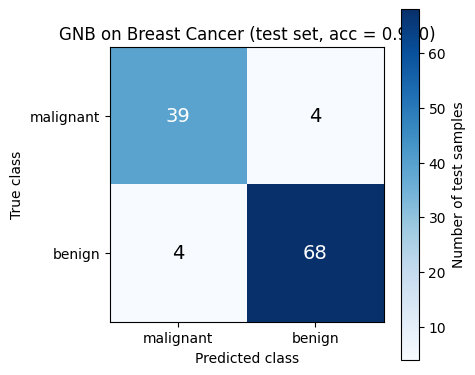

In [11]:
def plot_confusion_matrix(cm, labels, title):
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    cbar = fig.colorbar(im, ax=ax); cbar.set_label("Number of test samples")
    fig.tight_layout(); plt.show()

plot_confusion_matrix(cm, [class_names[c] for c in classes],
                      f"GNB on Breast Cancer (test set, acc = {acc:.3f})")

Samples (x -> true / predicted):
  x = 1  ->  0 / 0
  x = 2  ->  0 / 0
  x = 3  ->  0 / 0
  x = 6  ->  1 / 1
  x = 7  ->  1 / 1
  x = 8  ->  1 / 1
  x = 9  ->  1 / 1

Accuracy: 1.0000   (7/7 correct)

Confusion matrix (rows = true, cols = predicted):
[[3 0]
 [0 4]] 

class        precision    recall        f1
class 0         1.0000    1.0000    1.0000
class 1         1.0000    1.0000    1.0000
macro avg       1.0000    1.0000    1.0000


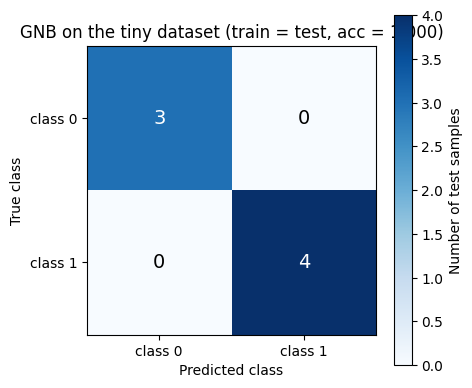

In [12]:
model_t = GaussianNaiveBayes().fit(Xt, yt)
yt_pred = model_t.predict(Xt)
classes_t = model_t.classes_
tiny_names = ["class 0", "class 1"]

print("Samples (x -> true / predicted):")
for xi, ti, pi in zip(Xt.ravel(), yt, yt_pred):
    print(f"  x = {xi:.0f}  ->  {ti} / {pi}" + ("" if ti == pi else "   <-- error"))

acc_t = accuracy(yt, yt_pred)
cm_t = confusion_matrix(yt, yt_pred, classes_t)
res_t = precision_recall_f1(yt, yt_pred, classes_t)

print(f"\nAccuracy: {acc_t:.4f}   ({int(np.sum(yt == yt_pred))}/{len(yt)} correct)\n")
print("Confusion matrix (rows = true, cols = predicted):")
print(cm_t, "\n")
print(f"{'class':<12}{'precision':>10}{'recall':>10}{'f1':>10}")
for i, c in enumerate(classes_t):
    print(f"{tiny_names[c]:<12}{res_t['precision'][i]:>10.4f}{res_t['recall'][i]:>10.4f}{res_t['f1'][i]:>10.4f}")
print(f"{'macro avg':<12}{res_t['macro_precision']:>10.4f}{res_t['macro_recall']:>10.4f}{res_t['macro_f1']:>10.4f}")

plot_confusion_matrix(cm_t, [tiny_names[c] for c in classes_t],
                      f"GNB on the tiny dataset (train = test, acc = {acc_t:.3f})")